# Example - Weighted Chain

## Setup

Run all cells from top to bottom. Tested package version: **0.9.0**.

In [1]:
from importlib.metadata import version, PackageNotFoundError
import importlib.util
import subprocess
import sys

# Install only when the required package version is missing.
try:
    installed = version("polyform_algebra")
except PackageNotFoundError:
    installed = None
if installed != "0.9.0":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                          "https://github.com/magin67/polyform_algebra/archive/refs/tags/v0.9.0.zip"])
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])


In [2]:
import polyform_algebra
assert polyform_algebra.get_version() == "0.9.0"
print("polyform_algebra", polyform_algebra.get_version())

polyform_algebra 0.9.0


This example reproduces the path $a-b-c$ with conductances $c_{ab}=1$, $c_{bc}=2$ from [Laplacian - graph, electrical network and quadratic form](https://magin67.github.io/pmg-notes/en/getting-started-and-foundations/introduction/laplacian---graph,-electrical-network-and-quadratic-form) and [Effective Resistance and Graph Geometry](https://magin67.github.io/pmg-notes/en/getting-started-and-foundations/introduction/effective-resistance-and-graph-geometry#example-a-three-vertex-path). Resistances are evaluated through the metric polyform; current equations provide an independent check.



This example was checked with `polyform_algebra 0.9.0`. Environment setup: [Installing the Library and Running Examples](https://magin67.github.io/pmg-notes/en/pythonexamples/installing-the-library-and-running-examples). Run the Python cells in order.

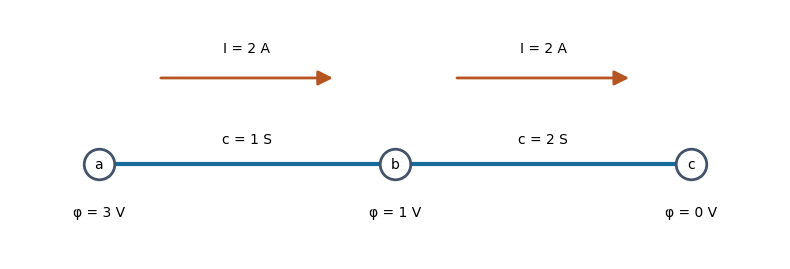

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot([0, 1, 2], [0, 0, 0], color="#176b9b", linewidth=3)
for x, label, voltage in [(0, "a", 3), (1, "b", 1), (2, "c", 0)]:
    ax.plot(x, 0, "o", markersize=22, color="white", markeredgecolor="#44536a", markeredgewidth=2)
    ax.text(x, 0, label, ha="center", va="center")
    ax.text(x, -.3, f"φ = {voltage} V", ha="center")
for x, conductance in [(0, 1), (1, 2)]:
    ax.text(x + .5, .12, f"c = {conductance} S", ha="center")
    ax.annotate("", (x + .8, .5), (x + .2, .5),
                arrowprops={"arrowstyle": "-|>", "mutation_scale": 22, "color": "#b65422", "lw": 2})
    ax.text(x + .5, .65, "I = 2 A", ha="center")
ax.set(xlim=(-.3, 2.3), ylim=(-.55, .9))
ax.axis("off")
plt.tight_layout()
plt.show()


## From graph to metric polyform

An edge weight is a conductance. Edge resistances are its reciprocal: $1$ and $1/2$. There is no direct edge $ac$.

In [4]:
import networkx as nx
from polyform_algebra import Polyform, quForm

# Edge weights are conductances.
graph = nx.Graph()
graph.add_weighted_edges_from([("a", "b", 1), ("b", "c", 2)])
laplacian, points = Polyform.from_networkx(graph, return_points="dict")
metric = laplacian.exp()

print("tau =", metric.potential(quForm.one()))
for i, j in [("a", "b"), ("b", "c"), ("a", "c")]:
    form = quForm([(points[i], points[j])])
    print(f"R{i}{j} =", metric.norm(form))

tau = 2.0
Rab = 1.0
Rbc = 0.5
Rac = 1.5


The form $f_{ij}=[a_j-a_i]^2$ is the quadratic form of an edge. Nilpotence of edge forms gives

$$
L=f_{ab}+2f_{bc},\qquad
M=\exp L=(e+f_{ab})(e+2f_{bc})
$$
This is the exponential in the algebra of forms, not the matrix exponential. The value `potential(quForm.one())` gives the spanning-tree coefficient, while `norm(form)` gives the normalized metric evaluation.

| Quantity | Result | Explanation |
|---|---:|---|
| $\tau$ | $2$ | The unique spanning tree has weight $1\cdot2$ |
| $R_{ab}$ | $1$ | Resistance of the first edge |
| $R_{bc}$ | $1/2$ | Resistance of the second edge |
| $R_{ac}$ | $3/2$ | Sum of series resistances |

The existence of $R_{ac}$ does not imply an edge $ac$. In the resistance embedding this is a squared distance; the distance itself is $\sqrt{3/2}$.

## Matrix, currents, and power

The `to_matrix()` method returns a matrix and a point-to-index mapping. In vertex order $a,b,c$:

$$
\mathbf L=
\begin{pmatrix}
1&-1&0\\
-1&3&-2\\
0&-2&2
\end{pmatrix}
$$
Reproduce the first note's experiment: inject 2 A at vertex a, remove 2 A at vertex c, and choose $\varphi_c=0$.

In [5]:
import numpy as np

matrix, index = laplacian.to_matrix()
# Reorder rows and columns explicitly as vertices a, b, c.
order = [index[points[label]] for label in ("a", "b", "c")]
matrix = np.asarray(matrix[np.ix_(order, order)], dtype=float)
# Ground vertex c and inject 2 A at vertex a.
current = np.array([2.0, 0.0, -2.0])
potential = np.append(np.linalg.solve(matrix[:2, :2], current[:2]), 0.0)
print("potentials =", potential)
print("power =", potential @ matrix @ potential)

potentials = [3. 1. 0.]
power = 6.0


The result is

$$
\varphi=(3,1,0)^{\mathsf T},\qquad
I_{ab}=I_{bc}=2,\qquad
\mathcal Q=1(3-1)^2+2(1-0)^2=6
$$
Power balance also gives $\varphi^{\mathsf T}J=6$ and $I^2R_{ac}=4\cdot3/2=6$. With conductances in siemens, potentials are in volts and power in watts. The package supplies the matrix; NumPy solves the current equations. Below, this matrix is compared with an independent reference built directly from the conductances.

## Checks

Three mathematical tests check the matrix and resistances, spanning-tree coefficient and exponential factorization, current equations, and three ways of computing power. The independent reference constructs the Laplacian explicitly without converting polyforms: its cofactor gives $\tau$, while three unit-current solves check all pair resistances. General example checks also verify module execution and silent imports.

In [6]:
from math import isclose

reference = np.array([[1., -1., 0.], [-1., 3., -2.], [0., -2., 2.]])
assert np.allclose(matrix, reference)
assert np.allclose(reference @ potential, current)
assert np.allclose(potential, [3., 1., 0.])
assert isclose(float(metric.potential(quForm.one())), 2.)
assert isclose(float(metric.norm(quForm([(points["a"], points["c"])]))), 1.5)
assert isclose(float(potential @ reference @ potential), 6.)

## Try changing the input

Change the second conductance from 2 to 4. Obtain $R_{ac}=5/4$ and power 5 for the same current of 2 A.

These numerical checks concern this example and do not replace a general proof.